# Reliability, SLOs, and Incident Management for GenAI Systems

This course covers production reliability engineering for GenAI systems: how to define and measure SLIs/SLOs/SLAs, apply resilience patterns like circuit breakers and bulkheads, and run effective incident response and blameless postmortems. Four modules progress from reliability fundamentals through observability, failure handling, and operational excellence.

**Modules:**
1. [Module 01: Production Reliability Fundamentals](#module-01)
2. [Module 02: SLIs, SLOs, and SLAs for GenAI Services](#module-02)
3. [Module 03: Failure Handling and Resilience Patterns](#module-03)
4. [Module 04: Incident Response and Operational Excellence](#module-04)

In [1]:
from pathlib import Path
from IPython.display import HTML, display
import base64

def render_diagram(image_path, width=900):
    data = base64.b64encode(Path(image_path).read_bytes()).decode()
    display(HTML(f'<div style="text-align:center"><img src="data:image/png;base64,{data}" width="{width}"/></div>'))

<a id="module-01"></a>
## Module 01: Production Reliability Fundamentals

_Reliability for GenAI is not about uptime — it's about keeping latency, quality, and cost within agreed bounds while degrading gracefully under stress._

### Uptime Is Not Reliability

| Uptime Thinking | Reliability Thinking |
|---|---|
| HTTP 200 masks partial failure | P99 stays within SLO (error budget) |
| Averages hide tail latency and timeouts | Quality stays within acceptance bounds |
| "Green" ignores relevance and correctness | Degrade safely under stress |
| Restart first, amplify blast radius | Recover with bounded, reversible actions |

A 200 OK response says nothing about answer quality, retrieval relevance, or cost efficiency. Reliability engineering for GenAI requires tracking all three dimensions.

### GenAI Dependency Graph

A typical GenAI request flows through multiple dependency boundaries. The orchestrator is responsible for budget enforcement, policy application, and coordinating the retrieval and model layers.


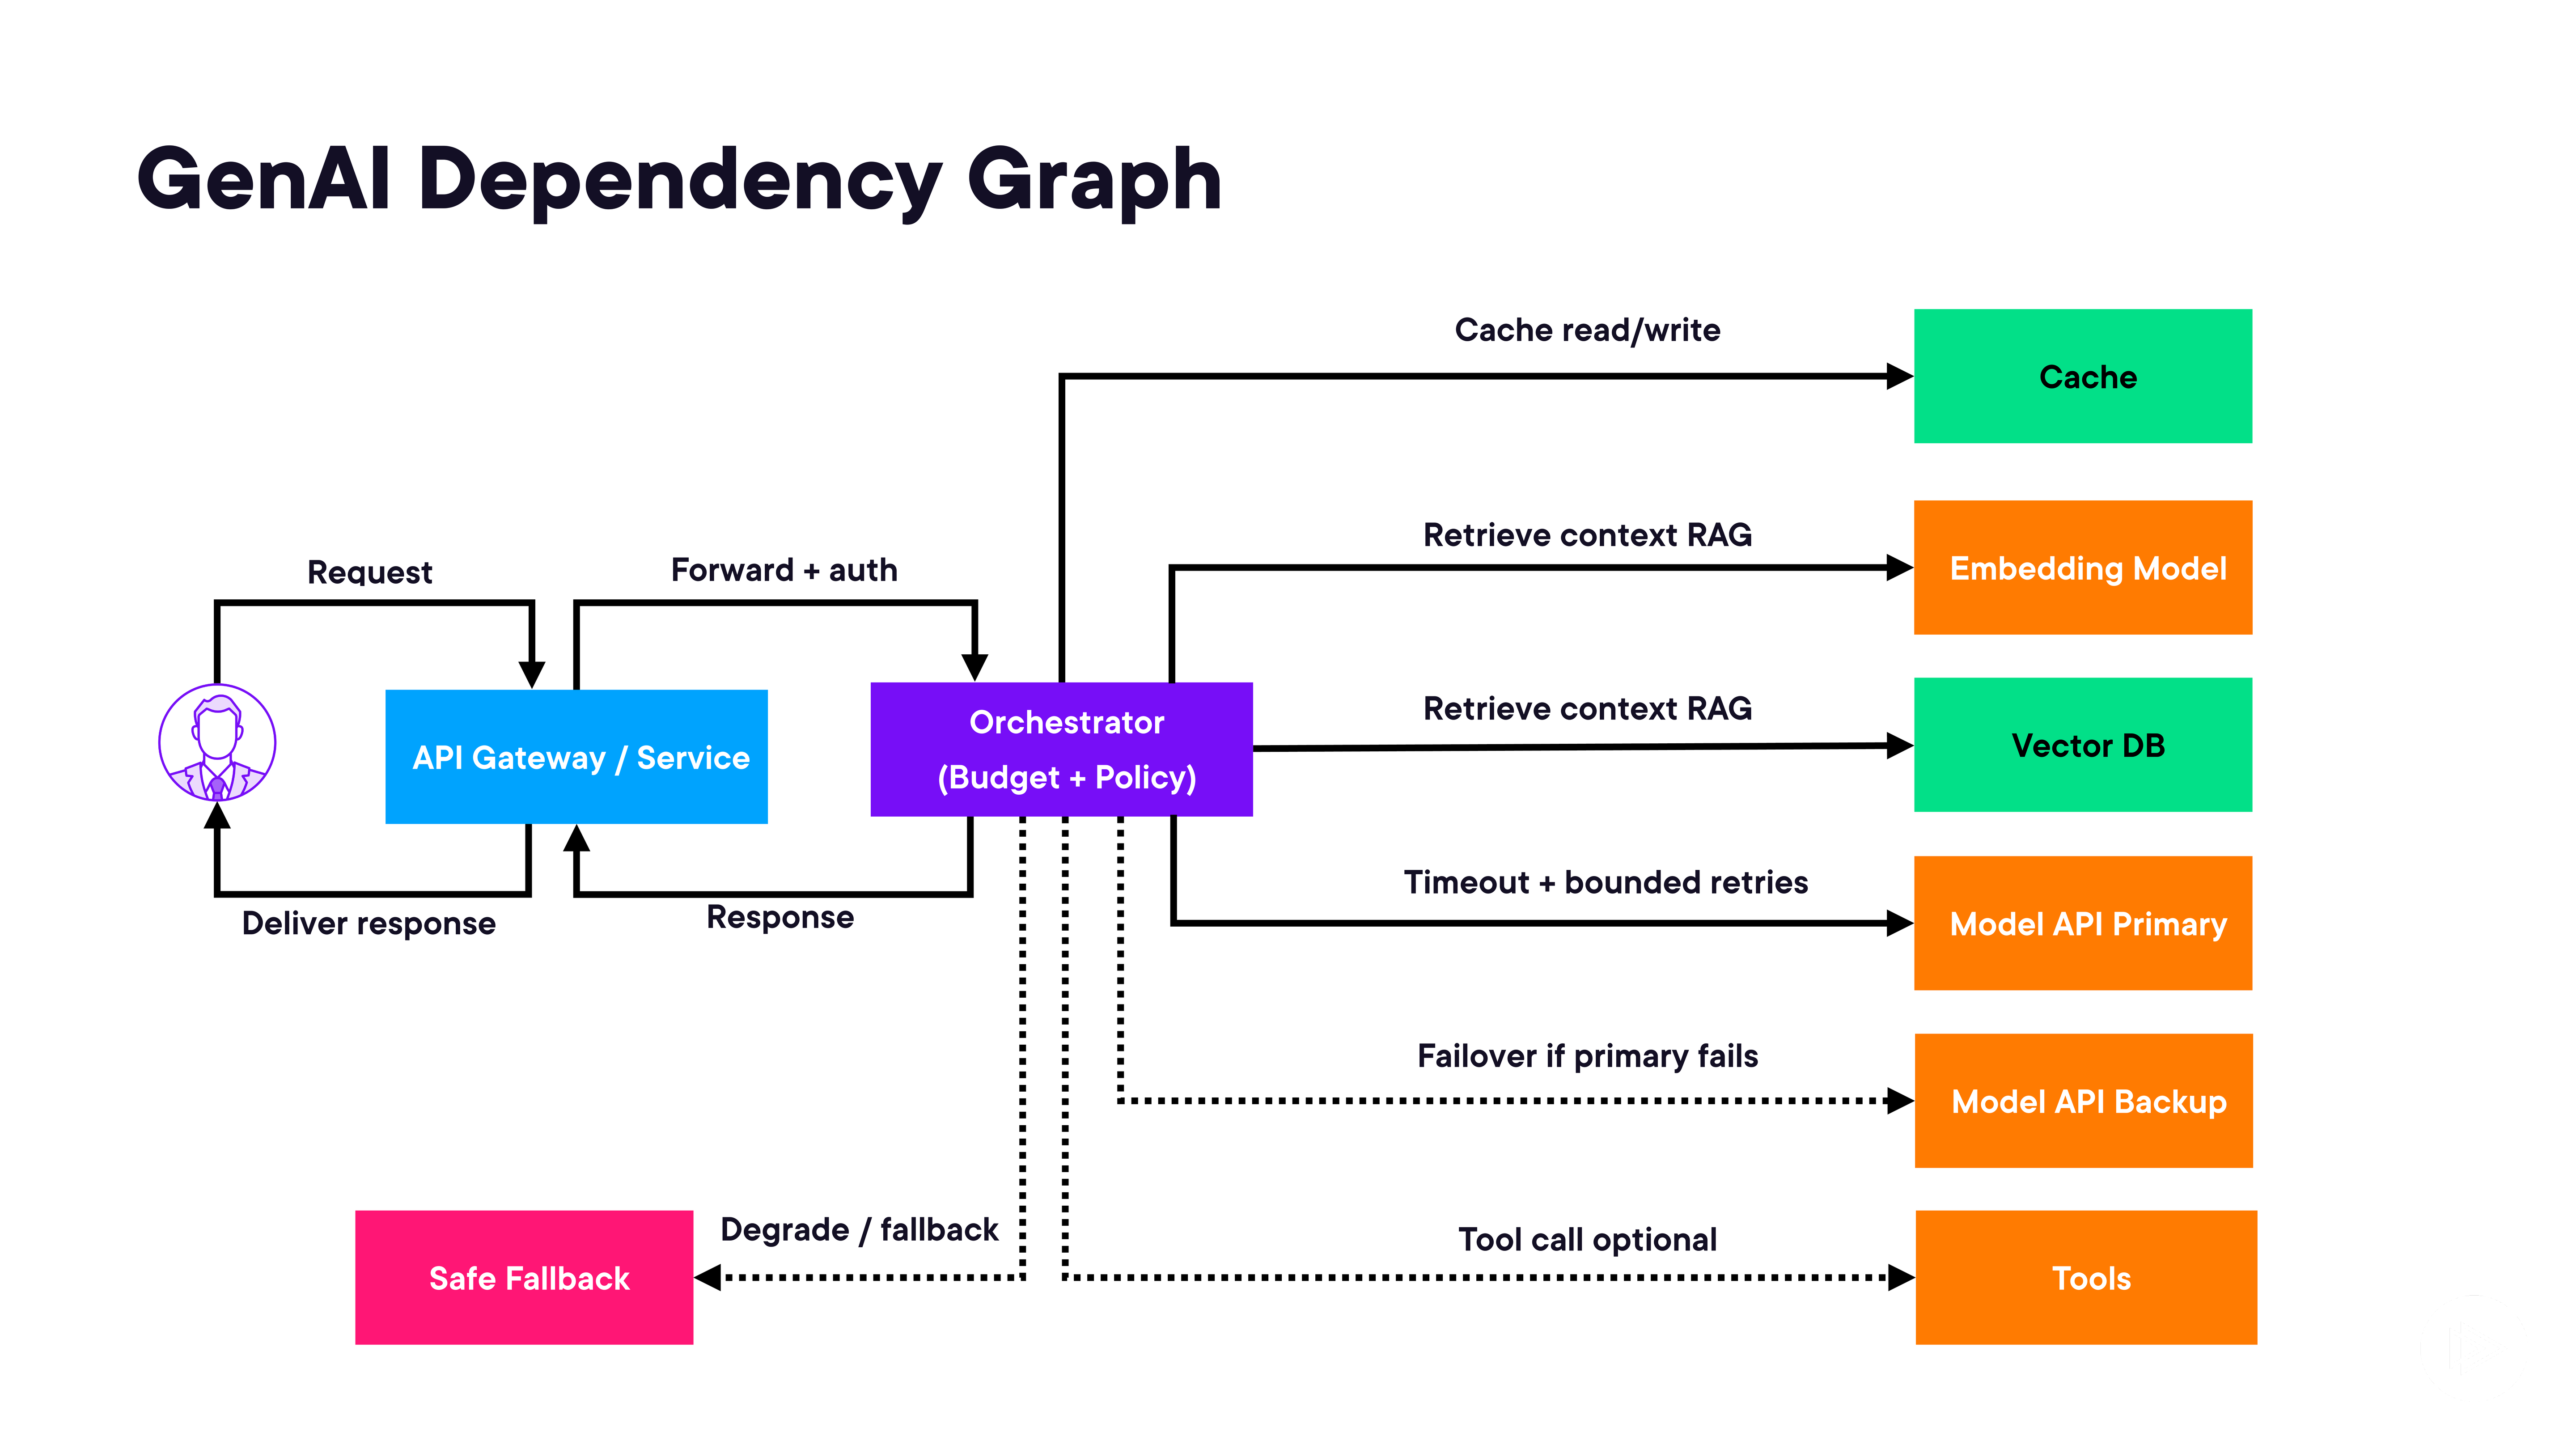

In [2]:
render_diagram(Path("assets/01-genai-dependency-graph.png"))

### Soft Failures That Break Trust

Hard errors (5xx, timeouts) trigger alerts. Soft failures erode user trust silently while dashboards stay green:

- **p95 → p99 latency creep** — tail latency grows, eroding SLAs and user trust before alerts fire
- **429 retry amplification** — throttle responses trigger retries that amplify load until throughput and cost collapse
- **Embedding drift** — stale or drifted embeddings return wrong chunks, producing confident but ungrounded answers
- **Silent quality regressions** — answer quality degrades without tripping any availability alert

These failures are invisible to uptime-only monitoring and require dedicated quality SLIs to detect.

### Graceful Degradation Ladder

When dependencies degrade, the system should shed capability in a controlled order rather than failing completely:

1. **Budget every outbound call** — enforce per-request time and cost budgets before they escape
2. **Break fast and avoid queues** — circuit-break failing dependencies, don't queue retries
3. **Reduce tools and context** — drop optional tool calls and trim retrieved context
4. **Use safe cached fallback** — serve a known-good cached response
5. **Shed load and protect core** — drop non-critical traffic to protect the critical path

Each step trades completeness for stability. The goal is to remain usable at reduced capability rather than fail entirely.

### Recovery Back In Bounds

**Recovery** means returning latency, quality, and cost to agreed SLO bounds — not just stopping the visible error.

**Proof signals required:**
- Sustained P99 latency within SLO window
- Grounded output rate back above threshold
- Cost per request back within budget range

Recovery is not declared until all three proof signals are stable, not just the one that triggered the incident.

### Failure Mode Analysis for RAG

Before incidents force reactive decisions, proactively rank reliability risks using a scored failure mode table.

**Why it works:** Structured risk scoring surfaces the highest-impact risks before they become incidents, and forces you to identify detection signals for each one.

**Output:** A scored table, top three risks by score, and the first mitigation to ship.

#### Dependency Failure Modes

**Performance and availability failures:**

| Component | Failure Mode | User Impact |
|---|---|---|
| Vector DB | Slow search | Latency blowup, cascades downstream |
| Model API | 429 throttling | Latency spikes, timeouts, degraded throughput |
| Model API | Timeout | Partial outage, tail latency spikes |

**Amplification and control-plane failures:**

| Component | Failure Mode | User Impact |
|---|---|---|
| Orchestrator | Unbounded tool fanout | Tail latency and cost explode per request |
| Vector DB | Empty retrieval | Wrong answers with "green" uptime |
| Orchestrator | Retry storm | Self-inflicted outage, queue growth |

#### Risk Scoring

Score each failure mode on three dimensions (1–5 each):

- **Impact** — user harm to latency, quality, or availability
- **Likelihood** — how often under normal and peak load
- **Detectability** — how fast you can detect before users report (higher = harder to detect)

```
Risk = Impact + Likelihood + (6 − Detectability)
```

**Worked example:** Empty retrieval — `5 + 4 + (6 − 2) = 13`

The `(6 − Detectability)` term means hard-to-detect failures score higher (worse), driving prioritization of detection investments.

#### Top Three Risks by Score

1. **Retrieval** — detect via `empty_topk_rate`, `relevance_score` drop, `citation_rate` decline
2. **Throttling** — detect via `429_rate`, `timeout_rate`, p95/p99 latency spikes
3. **Retries** — detect via `retries_per_request`, `queue_depth` growth, `attempts_per_request` inflation

#### Choosing the First Mitigation

| User Impact View | Error Budget View |
|---|---|
| Wrong answers erode trust fastest | Burn rate rising means act now |
| Latency breaks workflows | Protect SLO before features |
| Cost spikes break budgets | Stop retries and queues first |
| Pick highest combined harm | Stabilize then optimize |

**First mitigation for empty retrieval:** If `topK_count = 0` or `topK_score` below threshold, return Safe Fallback. Track `empty_topk_rate`, `low_score_rate`, and `safe_fallback_rate` as proof.

### Dependency Boundaries and Stress Signals

Each boundary in the GenAI dependency graph has distinct stress signals and alert indicators to monitor.


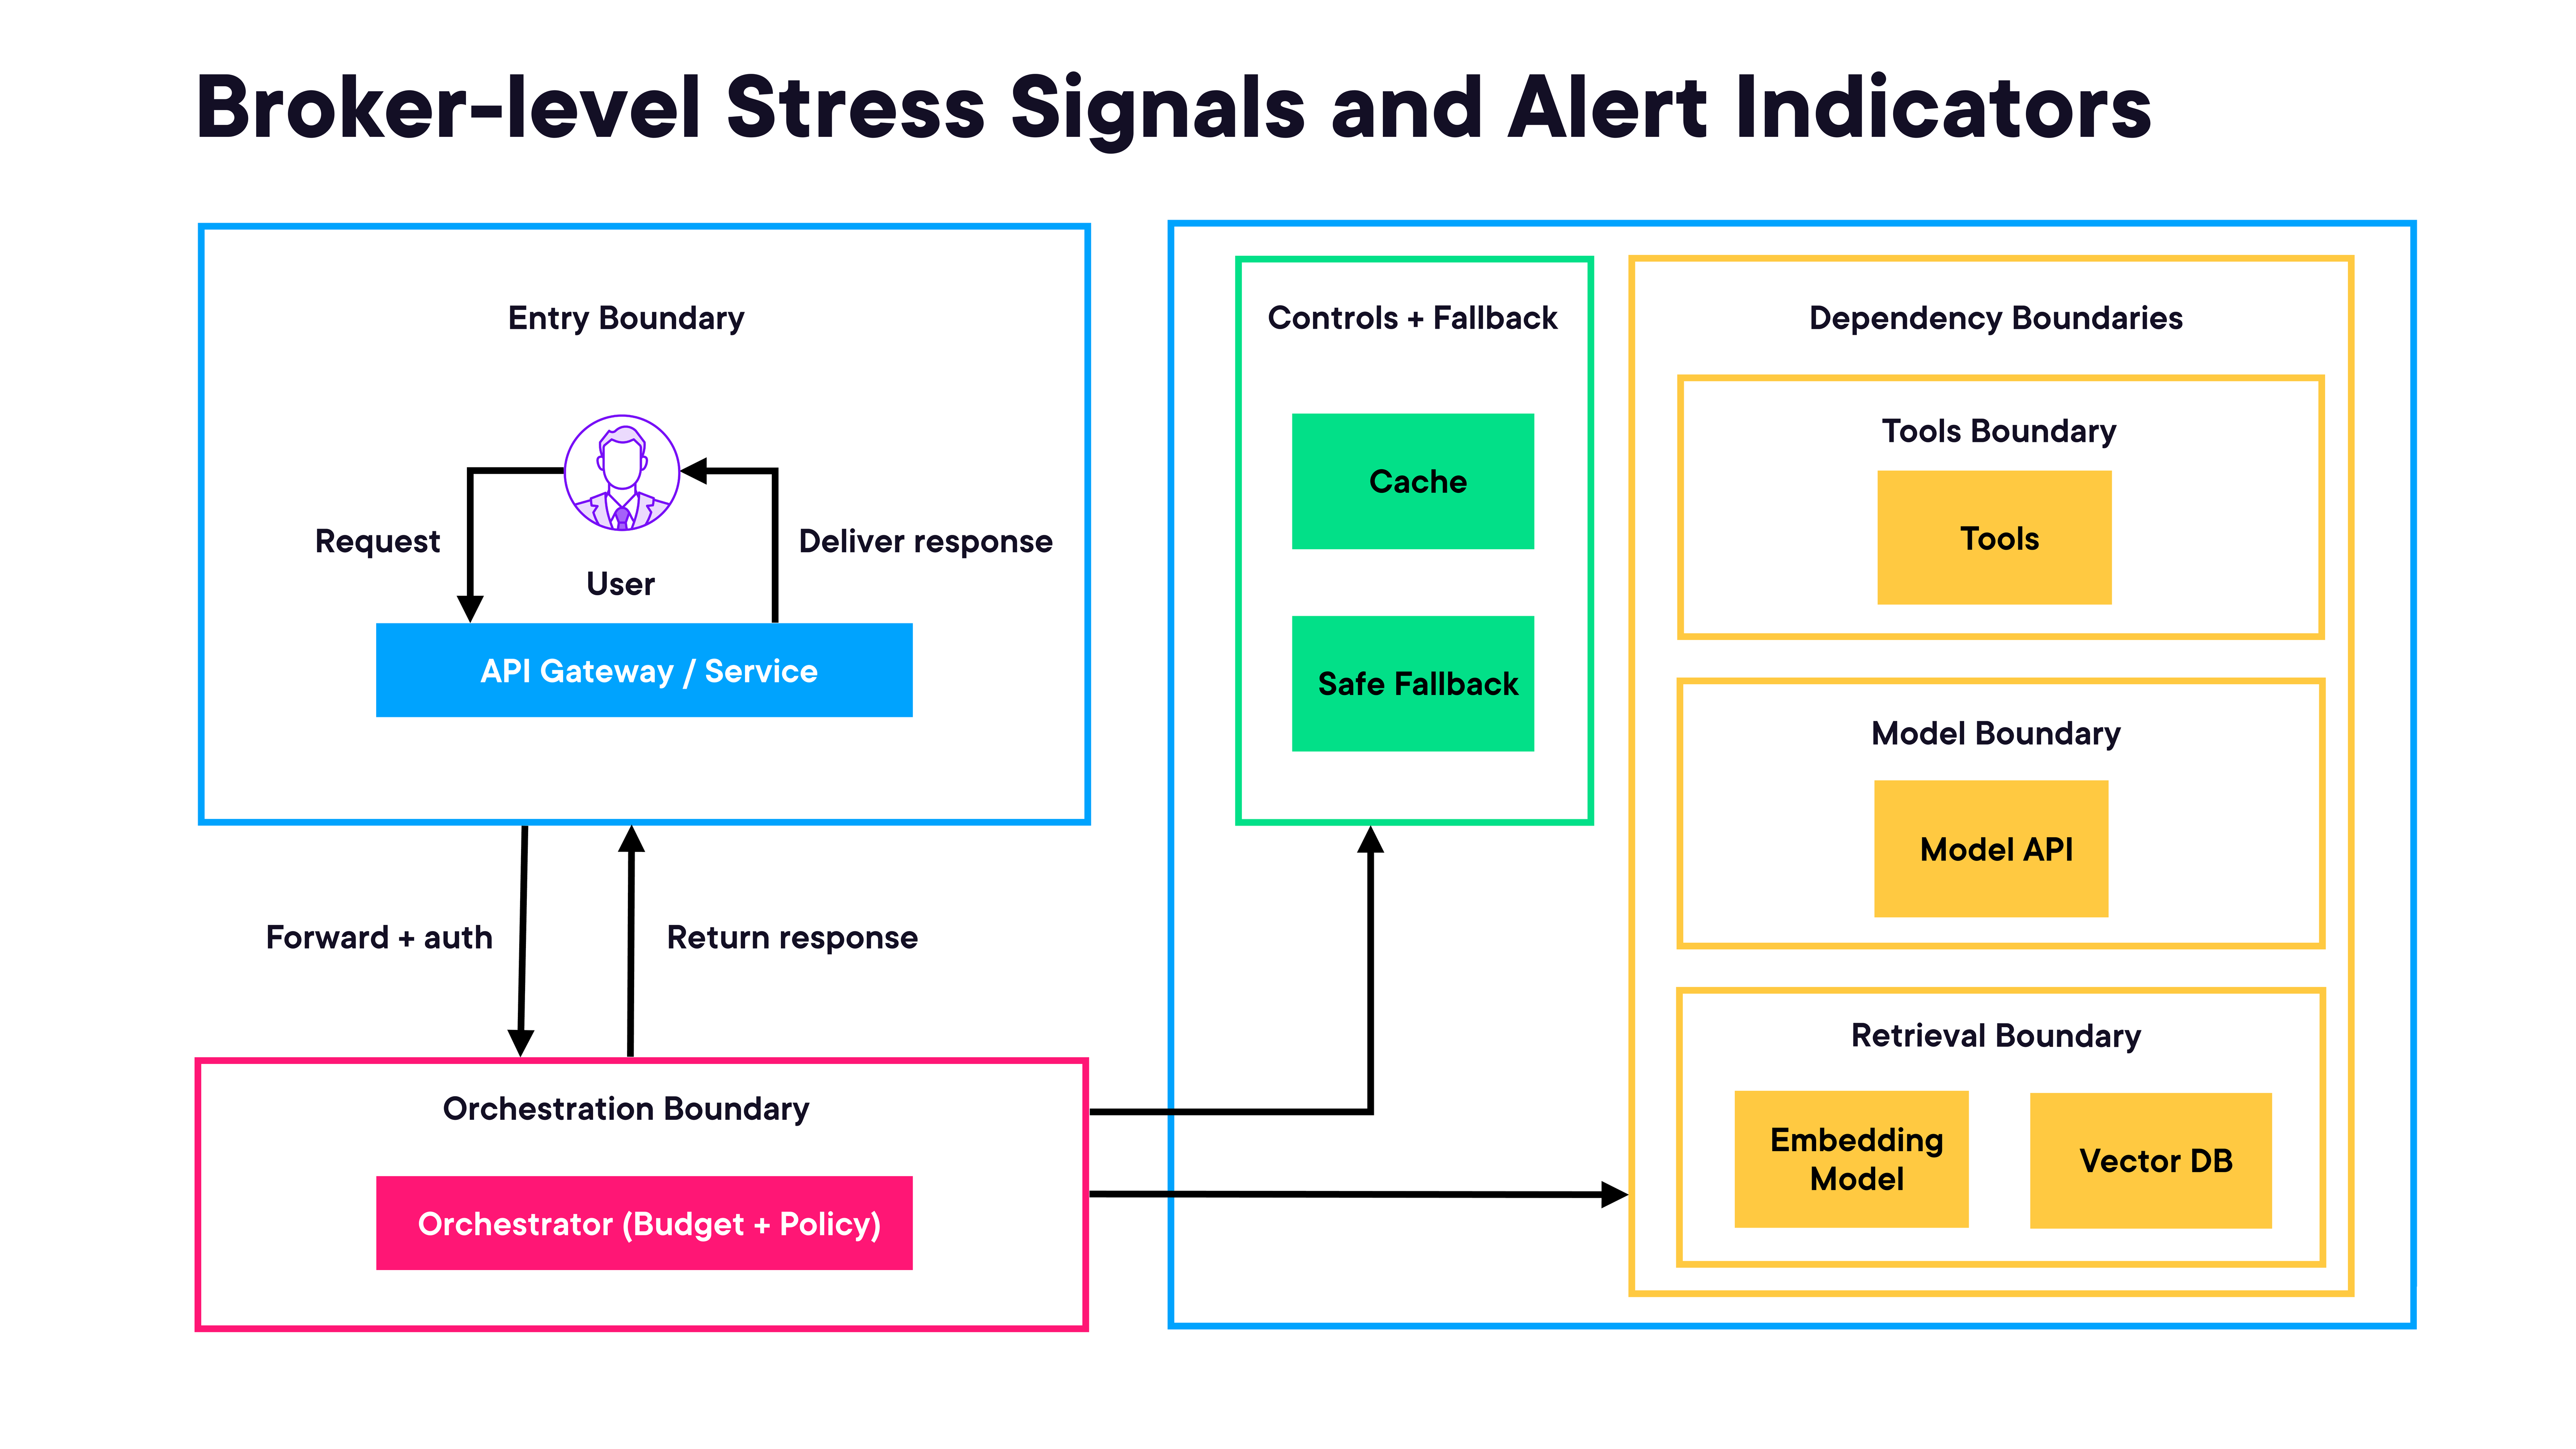

In [3]:
render_diagram(Path("assets/02-dependency-boundaries-stress-signals.png"))

### Health Checks and Synthetic Probes

A GenAI service can return HTTP 200 while quality silently collapses. Standard liveness/readiness probes miss soft failures entirely.

#### Four Levels of "Healthy"

| Level | Description |
|---|---|
| **Liveness** | Process is running and serving a basic route without crashing or deadlocking |
| **Readiness** | Safe to accept traffic with configs loaded, warm state ready, and queues stable |
| **Dependency health** | Model, retrieval, and tools respond within latency budgets and error thresholds |
| **Synthetic probe** | Run a known request and assert retrieval, model behavior, and fallback rules |

Only the synthetic probe catches soft failures. The others confirm infrastructure is up, not that the service produces correct outputs.

#### What the Synthetic Probe Must Validate

| Check | Pass Criteria | Why It Catches Soft Failures |
|---|---|---|
| Retrieval non-empty | Top-K > 0; context length meets minimum | Catches empty-context "green uptime" failures |
| Retrieval relevance | Top-K relevance score meets minimum | Detects drift, stale index, bad embeddings |
| Dependency behavior | No timeouts; no 429 surge; latency within budget | Finds brownouts before full outage |
| Output sanity | Answer returned or safe fallback; never silent success | Prevents confident nonsense responses |

#### Avoiding Fake Greens

- **Cache bypass** — if probes hit cache, you miss retrieval outages and quality regressions. Probes must bypass cache or report cache-hits separately.
- **No stubs** — if probes hit stubs, dashboards stay green while production fails quietly.
- **Treat empty retrieval as degraded** — low-confidence or empty retrieval is not a successful response.

### Demo: Health Checks and Synthetic Probes with OpenTelemetry

Implements health check endpoints and synthetic probe logic for a GenAI service using OpenTelemetry instrumentation. Demonstrates how to instrument liveness, readiness, and quality probes that detect soft failures before users report them.

See [`01-production-reliability-demos/`](01-production-reliability-demos/) for the full project.

<a id="module-02"></a>
## Module 02: SLIs, SLOs, and SLAs for GenAI Services

_Define what "good" means before production proves you didn't — SLIs measure it, SLOs set the bar, and SLAs make it contractual._

### GenAI SLI Domains

GenAI services require SLIs across three domains:

- **Availability** — measure uptime and failure rates objectively
- **Latency** — track P95 and P99 across request stages
- **Quality and cost** — measure usefulness proxies and unit economics

Standard availability SLIs miss the quality and cost dimensions entirely.

### Latency SLIs by Request Stage

Latency must be measured at each stage of the request pipeline — not just end-to-end. Each boundary has its own SLI.


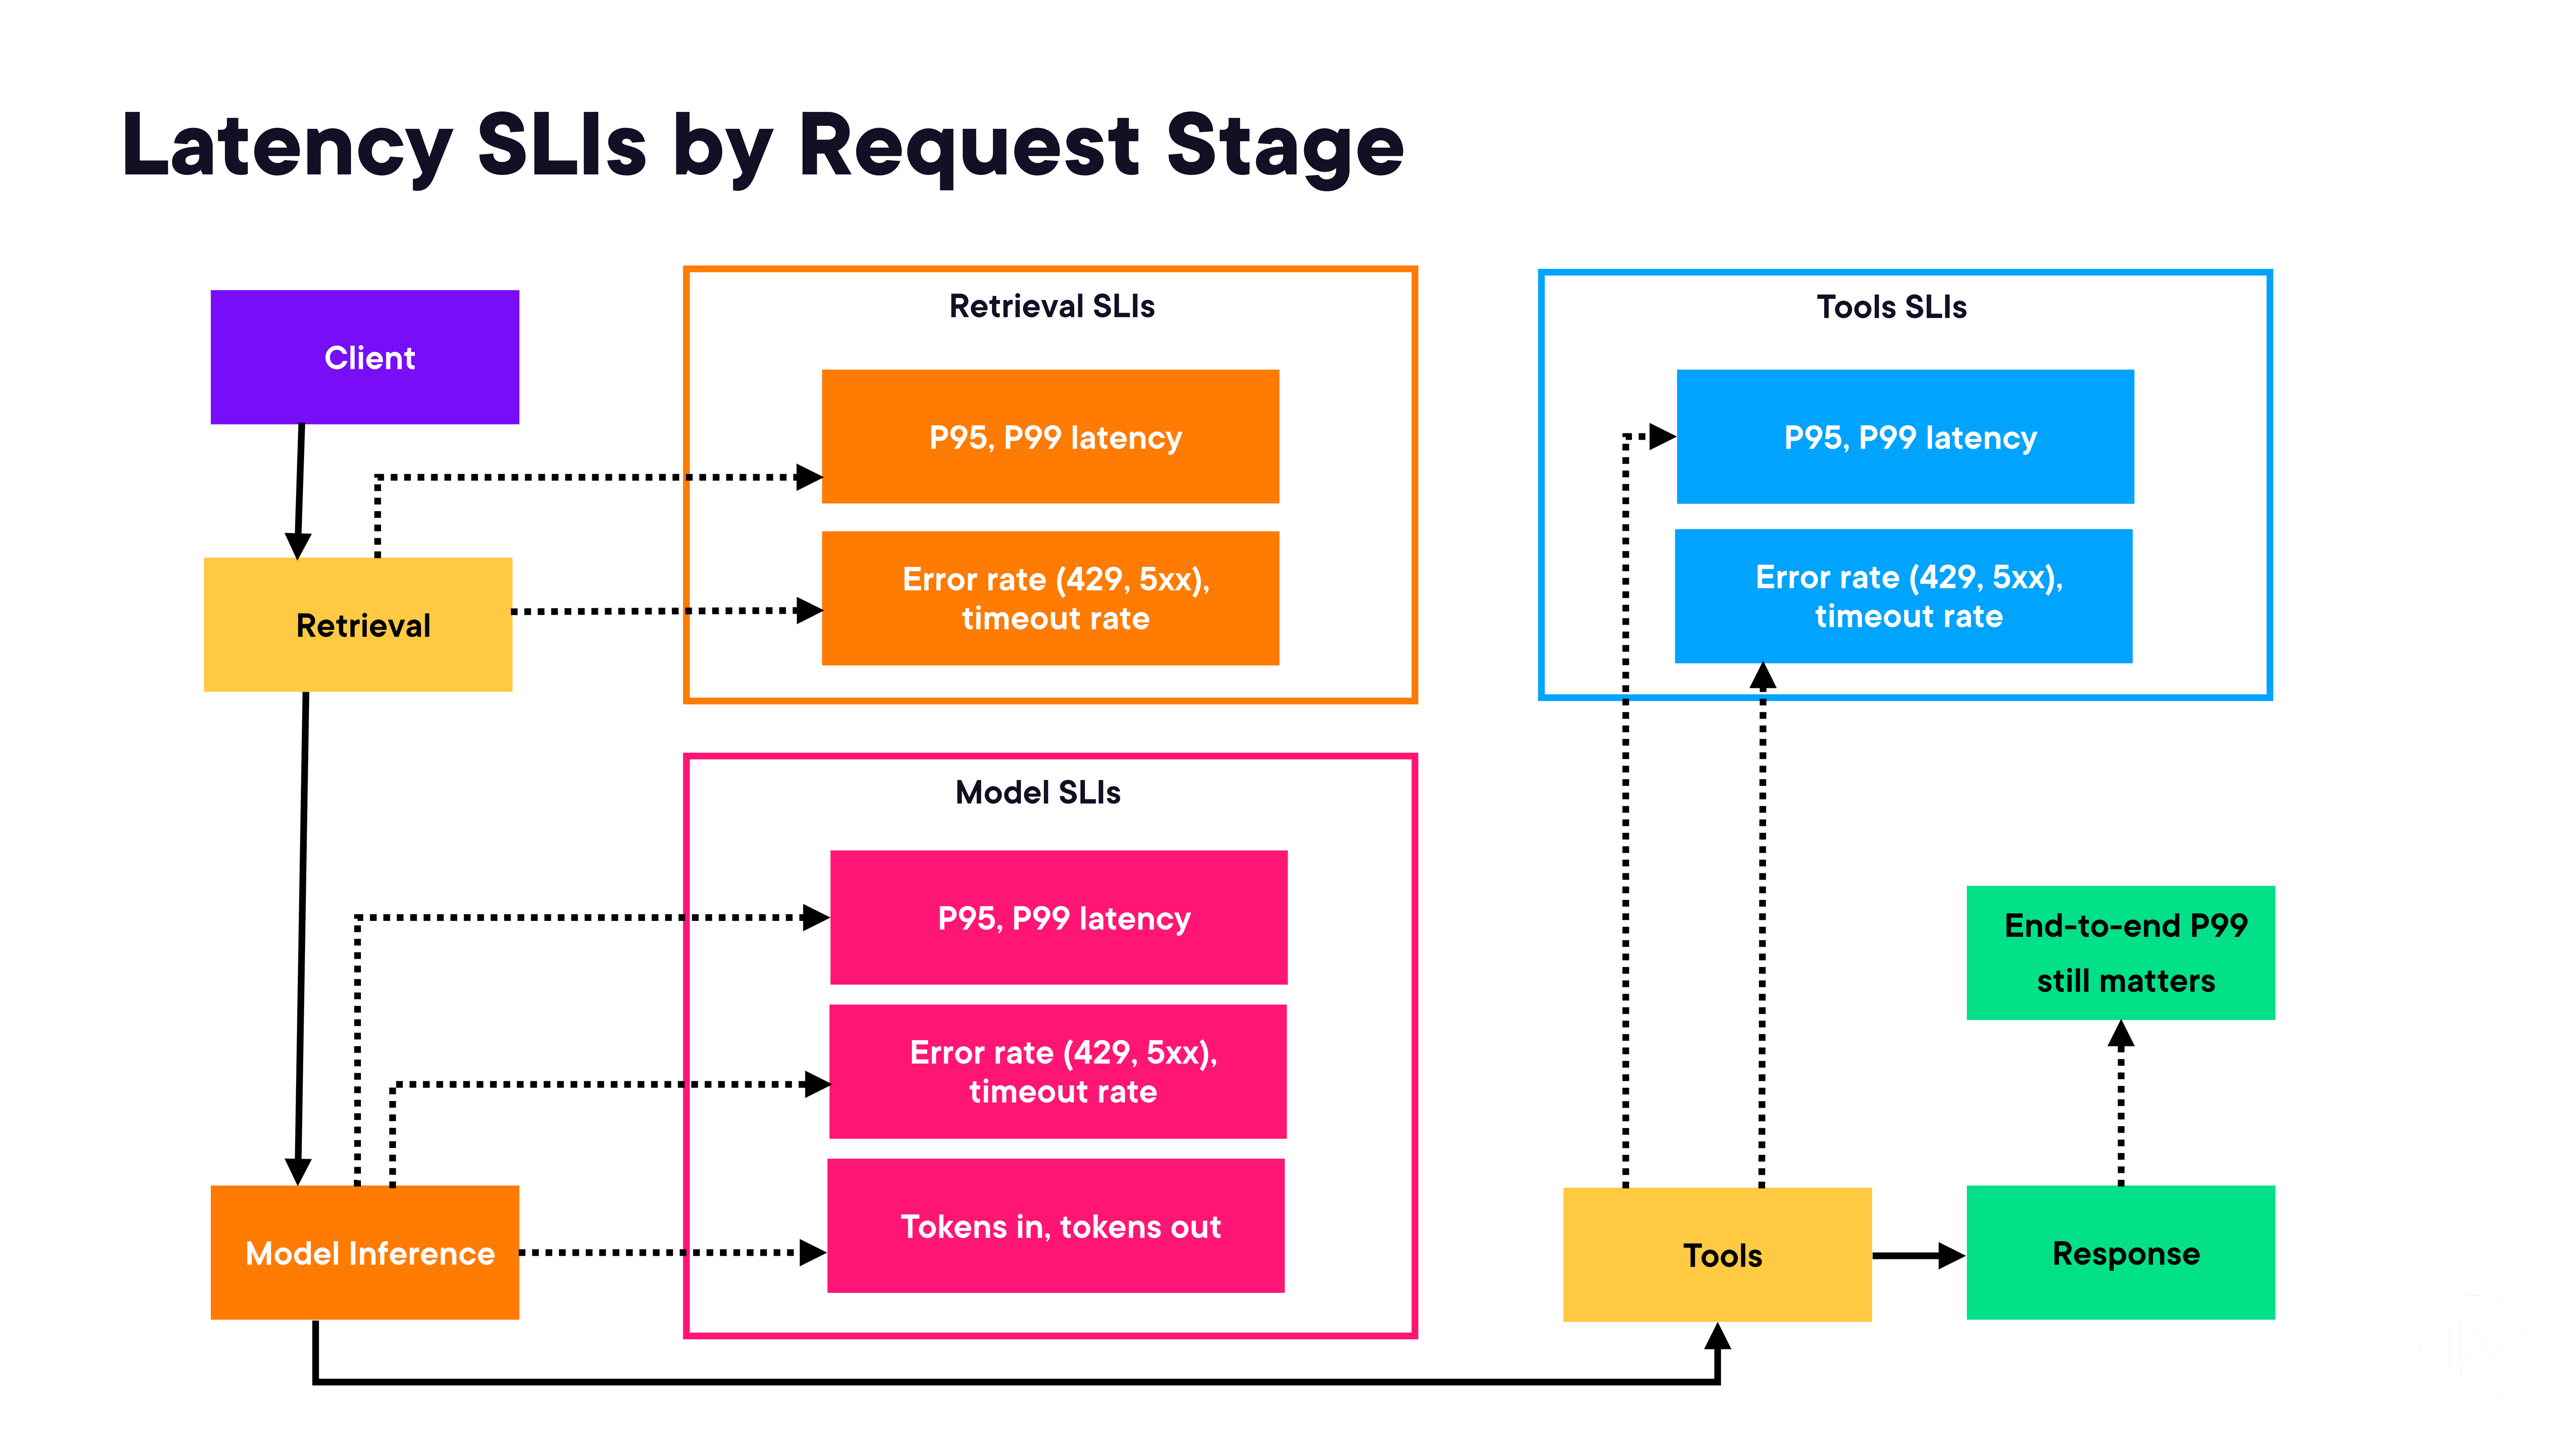

In [4]:
render_diagram(Path("assets/03-latency-slis-by-request-stage.png"))

**Latency SLI rules:**
- Break latency into model, retrieval, and tools stages
- Always report P95 and P99 separately — averages hide tail behavior
- Split queueing time from compute time; queueing latency indicates backpressure

### Error Rate SLIs

| Principle | Detail |
|---|---|
| Separate by component | Track model, retrieval, and tool errors independently |
| Separate by class | Track 4xx, 5xx, timeouts, and throttles independently |
| Attribute to boundaries | Attribute each failure to its dependency boundary, not the service as a whole |

**Hard errors vs. soft failures:**

| Hard Errors | Soft Failures |
|---|---|
| 5xx, timeouts, failed tool calls | Slow P99, low grounding rates |
| Trigger paging and incident response | Damage trust while dashboards look healthy |
| Need reliability fixes, not prompt tweaks | Need tuning, caching, routing policy changes |

### Online Quality Proxy SLIs

Quality cannot always be measured offline. Proxy signals track helpfulness without requiring human labels:

- **Retrieval Hit Rate** — percent of queries returning context above the relevance threshold
- **Grounded Answer Rate** — percent of answers supported by cited evidence
- **No Answer Rate** — percent of sessions safely abstaining when uncertain

### Cost SLIs

| SLI | What to Track |
|---|---|
| **Cost per Request** | Tokens, retrieval, and tool invocation costs; alert when median cost drifts upward |
| **Cost per Success** | Total cost divided by useful outcomes; exposes expensive failures hidden by uptime |

Cost per Success is more diagnostic than cost per request — it reveals when failures are silently inflating costs.

### SLI Definition Guardrails

- Define numerator and denominator precisely — ambiguous definitions break dashboard comparability
- Segment by model, route, and dependency boundary
- Version SLI specs and dashboard queries alongside code

### Demo: Instrument GenAI SLIs with Prometheus Metrics in FastAPI

Instruments a FastAPI-based GenAI service with Prometheus metrics covering latency (P95/P99 histograms), error rates by class and dependency boundary, and quality proxy metrics like retrieval hit rate and grounded answer rate.

See [`02-slis-slos-demos/`](02-slis-slos-demos/) for the full project.

### Setting SLOs from Baseline Telemetry

> "An SLO without a measurement method is just a promise."

**Process for setting SLO targets:**
1. Pull P95 and P99 latency distributions from real traffic
2. Compute error rate from the same real traffic
3. Segment by route, model, and dependency boundary
4. Validate steady-state behavior before choosing targets
5. Lock definitions in PromQL queries — the query IS the SLO

#### Interactive Chat vs. Batch Workflow SLOs

| Interactive Chat | Batch Workflow |
|---|---|
| P99 latency is user-visible | Completion time over strict P99 |
| Availability measured per request | Availability measured per job |
| Timeouts treated as failures | Retries acceptable within budget |
| Quality boundary blocks low-trust answers | Quality boundary gates final output |
| Fast burn alerts page on-call | Slow burn alerts create tickets |

These require separate SLO definitions — a single SLO for both hides which journey is degrading.

### Error Budgets

An error budget is the allowed number of bad events per measurement window, computed from the same SLO query.

**Error budget policy:**
- **Fast burn** (budget consuming rapidly) → pause releases, page on-call
- **Slow burn** (budget consuming steadily) → create tickets, plan fixes

Error budgets turn SLOs from monitoring thresholds into shipping decisions.

### Translating SLOs into SLA Inputs

SLA is contract language derived from SLOs, then validated by legal.

| SLA Input | Definition |
|---|---|
| **Uptime Guarantee** | Availability numerator, denominator, and exclusions — must match reporting |
| **Latency Threshold** | Percentile, measurement window, and endpoint scope — not just a single number |
| **Quality Boundary** | Proxy metric, target threshold, and allowed exceptions (unsafe or abstained answers) |

### Demo: SLO Dashboards, Burn-rate Alerts, and Feature Freeze Triggers

Builds Prometheus/Grafana SLO dashboards with multi-window burn rate alerts and a feature freeze trigger that automatically pauses releases when the error budget burn rate exceeds a threshold.

See [`02-slis-slos-demos/`](02-slis-slos-demos/) for the full project.

<a id="module-03"></a>
## Module 03: Failure Handling and Resilience Patterns

_Resilience patterns let a GenAI system absorb dependency failures and degrade gracefully rather than cascading to a full outage._

### Core Resilience Patterns

Five patterns form the foundation of GenAI service resilience:

- **Timeouts** — cap tail latency before queues explode
- **Bounded retries** — recover safely without triggering retry storms
- **Circuit breakers** — fail fast during dependency brownouts
- **Bulkheads** — isolate concurrency per dependency boundary
- **Fallbacks** — preserve partial value during partial outages

### Timeouts and Bounded Retries

**Timeouts first:** Set strict per-request time budgets that cap P99 before it drifts upward. A timeout that fires too late doesn't protect queues.

**Retry budget:** Retry only within the remaining time budget and attempt limits — never extend the deadline to accommodate retries.

**Safe retry rules:**
- Retry only on timeouts, 429s, and transient 5xx — not on all errors
- Use exponential backoff with jitter to desynchronize retry waves
- Stop at the retry limit and respect deadlines always
- Retry only idempotent operations — never retry side-effectful tool calls without idempotency keys

### Circuit Breaker States

| State | Behavior |
|---|---|
| **Closed** | Allows traffic while tracking failure rate and latency |
| **Open** | Fails fast, protecting downstream and preventing queue growth |
| **Half-open** | Probes recovery using a limited number of test requests |

The circuit breaker prevents a degraded dependency from absorbing unbounded load — it converts slow failures into fast failures, protecting the caller's queue and SLO.

### Bulkheads

Bulkheads limit blast radius by capping concurrency per dependency boundary rather than sharing a global thread/connection pool.

**Failures bulkheads prevent:**
- Single dependency starving all requests under load
- Retry storms amplifying brownouts into outages
- Queue growth masking incidents until users complain
- Cascading timeouts across services and dependencies

**Per-dependency limits:**
- Cap concurrent model and tool calls per pool
- Cap concurrent retrieval queries per worker pool
- Separate pools per dependency boundary and route
- Reserve headroom for probes and recovery traffic

### Fallbacks

When a dependency degrades, the service should return partial value rather than an error:

- **Retrieval failure** → serve a cached answer
- **Tool failure** → skip tools and return a minimal safe response
- **Low confidence** → abstain rather than return a hallucinated answer

### Demo: Retries and Circuit Breakers with HTTPX

Implements configurable retry policies and circuit breakers using HTTPX for outbound calls to the model API and retrieval layer. Demonstrates backoff with jitter and state transition monitoring.

See [`03-resilience-patterns-demos/`](03-resilience-patterns-demos/) for the full project.

### Graceful Degradation

**Goals:**
- Stay useful when retrieval or tools degrade
- Prefer predictable output over perfect output
- Make degraded mode visible and reversible

#### Degraded Response Selection

| Retrieval Degrades | Tools Degrade |
|---|---|
| Serve cached answers for known, stable queries | Skip tools and answer from available context |
| Return partial answers with reduced retrieved context | Use local stubs for non-critical tool dependencies |
| Ask clarifying questions when user intent unclear | Safe-abstain when required tool output is missing |
| Signal degraded mode and log fallback reason | Record selected fallback path for audit |

#### Redis Cache as First Fallback

```python
# Cache last known good answer with TTL
# Key by prompt template and context version
# Serve cache when retrieval times out
# Emit degraded flag for observability
cache_key = f"{prompt_template_hash}:{context_version}"
if retrieval_timeout:
    cached = redis.get(cache_key)
    if cached:
        return cached, degraded=True
```

**Caching rules:**
- Key by prompt template hash and context version — not raw prompt text
- Always emit a `degraded=True` flag so downstream observability knows
- TTL must be short enough that stale cache doesn't mask a prolonged outage

### Idempotent Tool Calls

Retries can repeat tool actions and corrupt user state. Idempotency keys make retries safe across network failures.

**Design:**
1. Generate an idempotency key per logical user action
2. Store key and status in Redis with TTL
3. On retry, return the stored result immediately without re-executing the tool
4. Scope keys by tool and tenant context
5. Track status: `in-progress`, `succeeded`, `failed`, `expired`

### Demo: Chaos Testing with Toxiproxy, Redis, and Fallbacks

Injects network failures and latency using Toxiproxy to validate that circuit breakers, Redis-backed fallbacks, and graceful degradation logic behave correctly under dependency failures.

See [`03-resilience-patterns-demos/`](03-resilience-patterns-demos/) for the full project.

<a id="module-04"></a>
## Module 04: Incident Response and Operational Excellence

_Effective incident response depends on clear roles, evidence-driven investigation, and blameless reviews that produce lasting fixes._

### Incident Lifecycle Phases

1. **Detect** — confirm real user-impacting degradation (not just alert noise)
2. **Triage** — define scope, severity, owner, and next action; start timeline; set update cadence
3. **Investigate** — identify likely failure domain using metrics, traces, and logs
4. **Mitigate** — stop the harm: shed load, degrade features, or roll back safely
5. **Resolve** — fix the underlying issue; verify recovery on user journeys and SLO signals
6. **Review** — write the timeline, confirm root cause, assign owners with due dates

**Detection vs. Triage distinction:**
- Detection confirms real user impact using SLO signals, key journeys, and recent-change awareness
- Triage defines scope, severity, owner, and next action — it is separate from detection and must not be skipped

### On-call Roles

| Role | Responsibility |
|---|---|
| **Incident commander** | Owns priorities, decisions, and timebox disciplines |
| **Comms owner** | Shares impact, ETA, and update cadence with stakeholders |
| **Ops owner** | Runs mitigations, rollbacks, and safe changes |
| **Subject expert** | Narrows cause, verifies fixes, prevents relapse |

### Severity Classification

Severity reflects user impact, not internal system state.

| High Severity | Lower Severity |
|---|---|
| Requests failing or timing out | Degraded for a small cohort |
| Chat unusable from P99 latency | Quality regression with guardrails active |
| Hallucinations causing user harm | Cost spike without user harm |
| Unsafe output policy breach | Single dependency brownout, contained |
| Broad cohort or key tenant affected | Clear mitigation path without rollback |

### Evidence Collection and Investigation

**Signal types and their role:**

- **Metrics** — define start time, scope, and user impact trend; show blast radius
- **Traces** — show which dependency slowed, failed, or retried; where latency accumulates across spans
- **Logs** — confirm error details, recent config diffs, and deploy evidence

Correlate all three signals before guessing at root cause. A metric spike alone is not a diagnosis.

### Correlating Three Signal Types


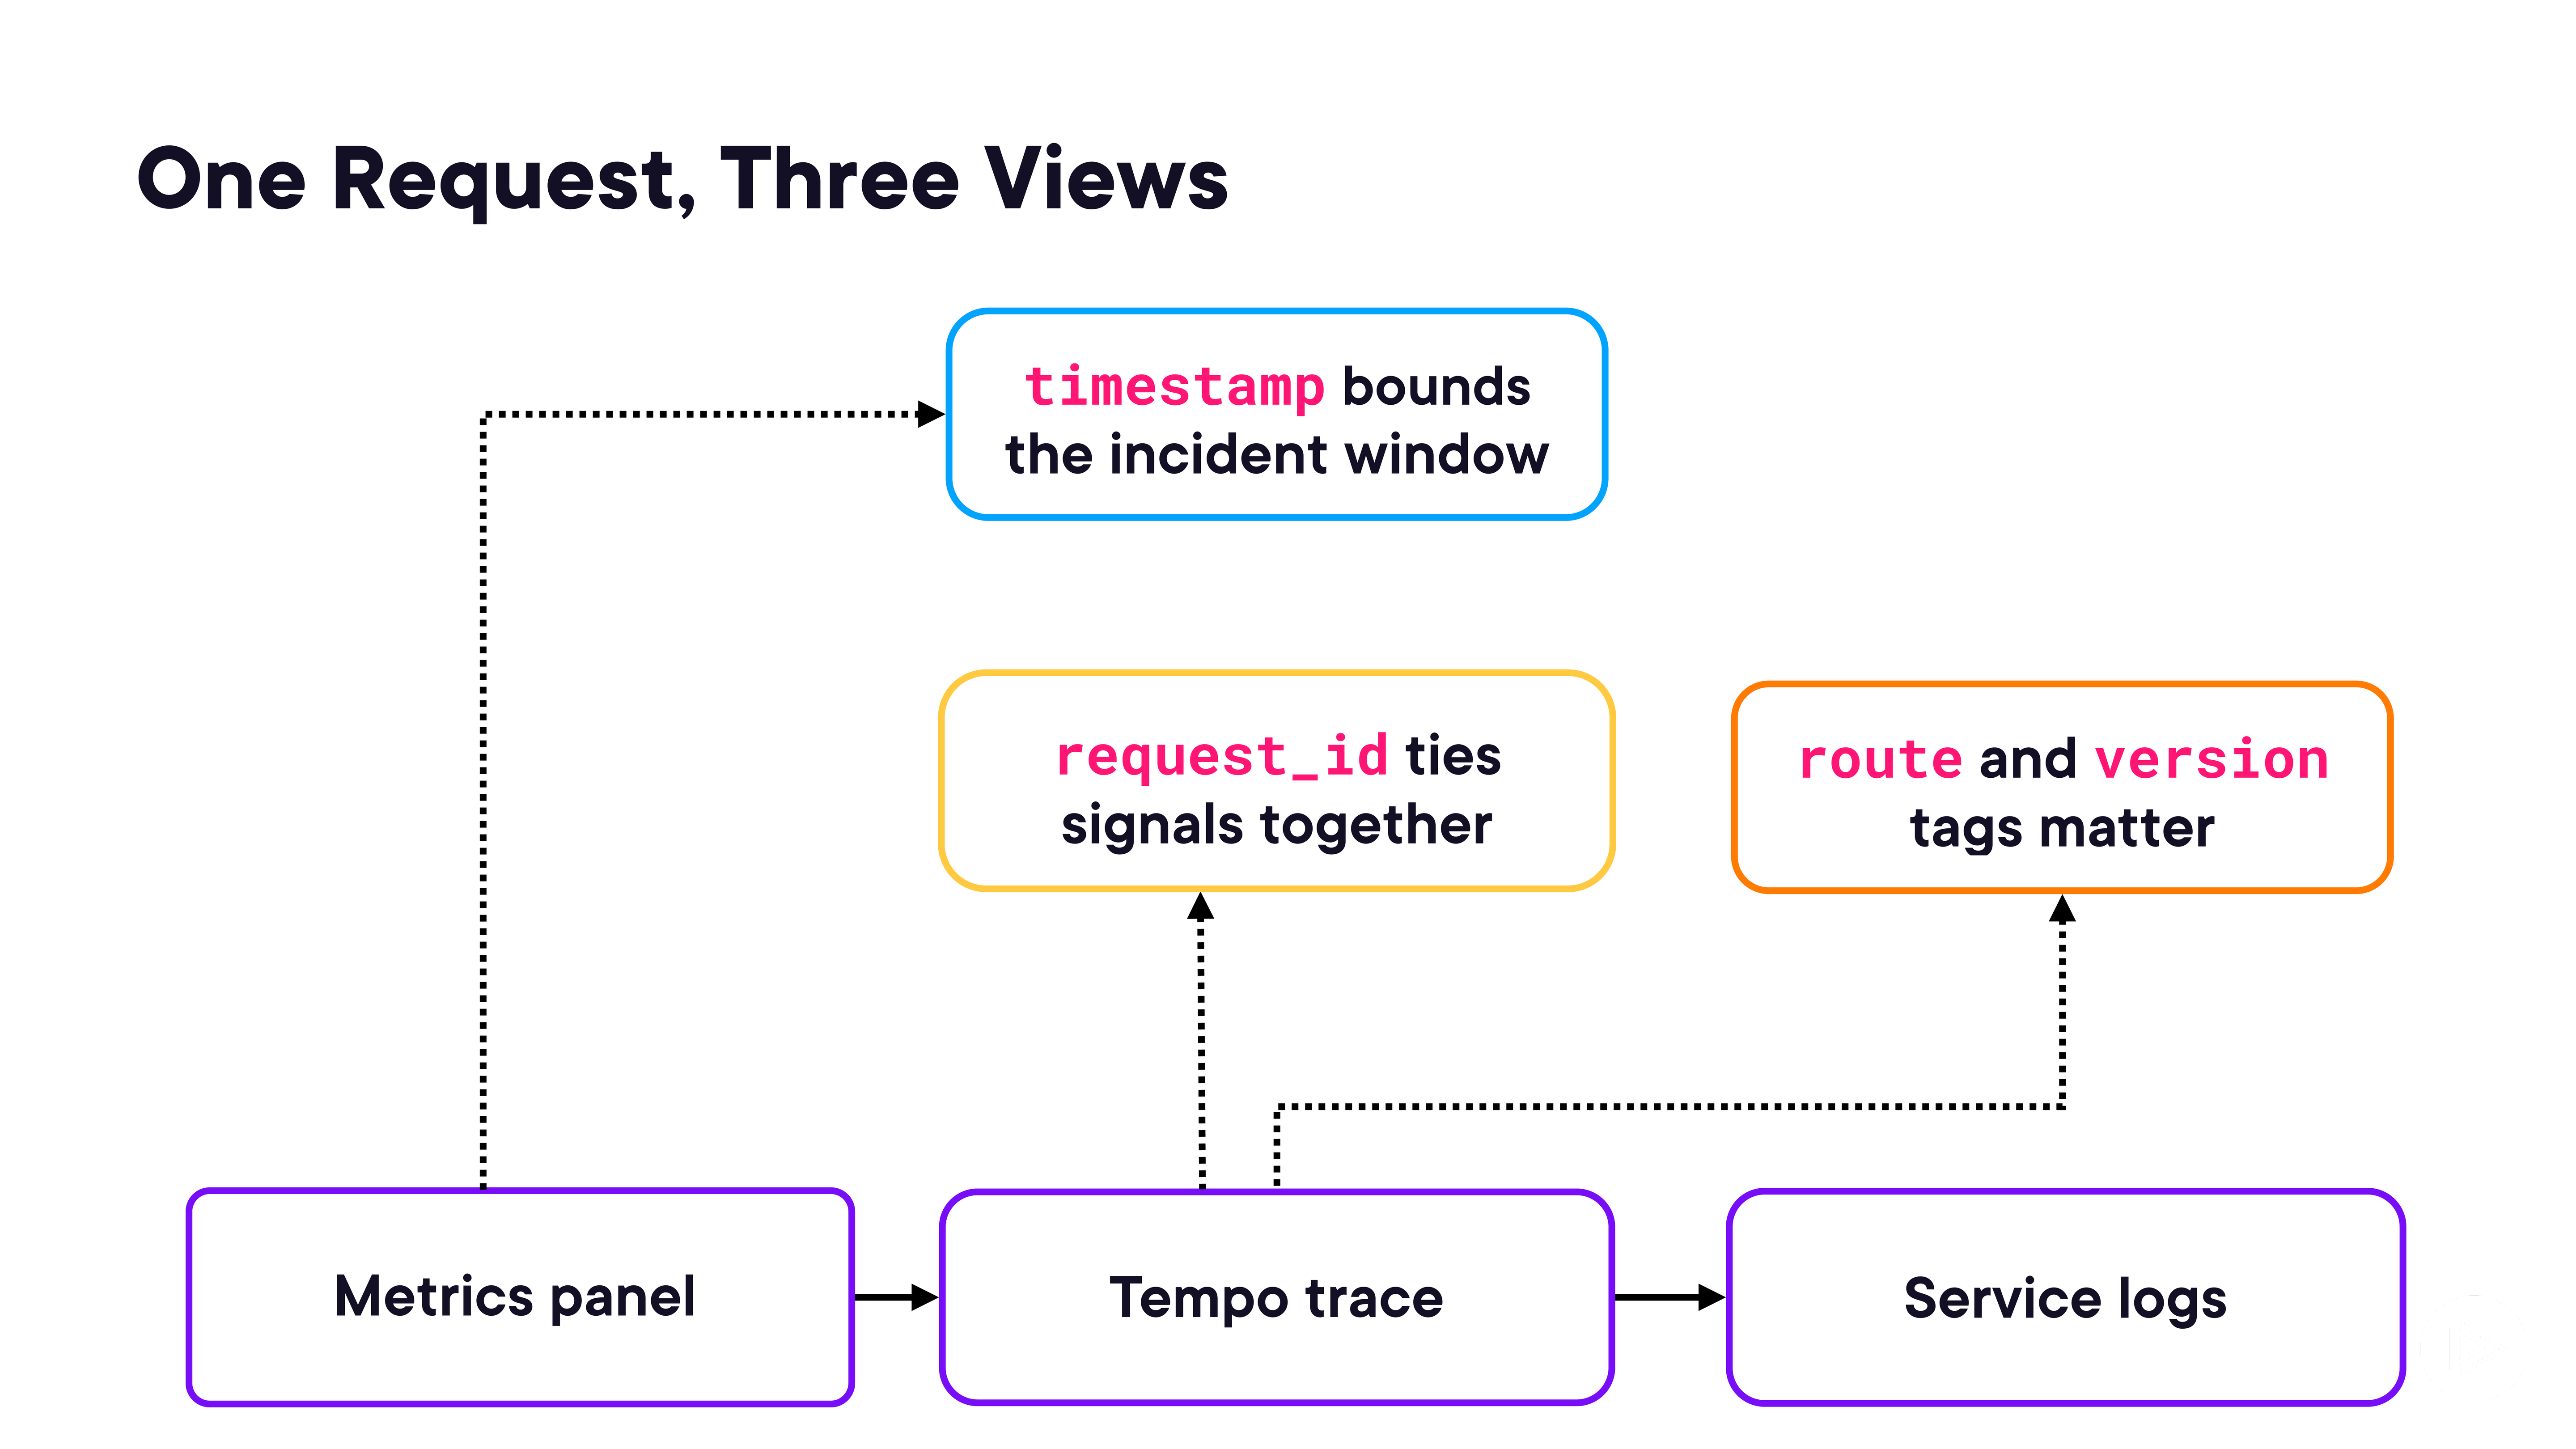

In [5]:
render_diagram(Path("assets/04-one-request-three-views.png"))

The three views are correlated via shared identifiers:
- `timestamp` bounds the incident window — use the first bad metric timestamp to scope the trace search
- `request_id` ties all three signals together — a single request ID links the metric, trace, and log entry
- `route` and `version` tags scope the blast radius — which routes and which deployed versions are affected

### Retrieval Drift: Symptom vs. Cause

Retrieval drift is a common soft failure that requires distinguishing observed symptoms from root causes.

**What you observe (symptoms):**
- Retrieval hit rate drops
- Grounded answer rate drops
- No answer rate rises
- Top queries shift suddenly

**What might cause it (root causes):**
- New index snapshot deployed
- Thresholds or filters changed in config
- Embeddings model version changed
- Prompt retrieval query changed

Do not act on symptoms. Identify the cause before applying a fix.

### Tempo Workflow for Soft Failures

1. Filter traces by route, status, and version tags
2. Open the retrieval span and inspect attributes and timing
3. Copy `trace_id` and capture the first bad timestamp
4. Pivot to service logs using `trace_id` and the time window
5. Correlate with deploy or config change at that exact timestamp

**Correlation rule:** Pick the first bad minute, lock the window, match deploy or config change time to symptoms, then validate using before/after traces — not guesses.

### Writing the Investigation Timeline

A complete investigation timeline contains:

- Start time, detection signal, and initial severity
- Sampled requests with `trace_id` values as evidence
- Span timings and matching log lines
- Root cause stated clearly, separate from observed symptoms
- Fix applied and proof of recovered signals (metric, trace, log)

The timeline is the artifact that makes postmortems actionable and prevents recurrence.

### Demo: Alerting and Escalation with Prometheus AlertManager

Configures Prometheus AlertManager with routing rules, severity-based escalation, and on-call notification policies for a GenAI service. Demonstrates multi-window alert rules that page on fast burn and ticket on slow burn.

See [`04-incident-response-demos/`](04-incident-response-demos/) for the full project.

### Demo: Blameless Postmortems, MTTR Metrics, and Reliability Backlogs

Implements a postmortem workflow with structured templates, MTTR tracking via Prometheus metrics, and a reliability backlog process that converts postmortem action items into tracked work items.

See [`04-incident-response-demos/`](04-incident-response-demos/) for the full project.